# Análisis de producción de pollos de engorde (broiler) — Monterrey, Casanare, 2021
Análisis de los lotes **L01 a L05**: conversión alimenticia, consumo por fase frente a la referencia, mortalidad, agua, ingresos y **calidad de datos**.
Fuente: `data/datos_largos.csv` (generado por `src/limpieza_pollos.py`) y `data/referencia_granja.csv` (curva de referencia de la granja).
> Las cifras marcadas **(estimado)** dependen de supuestos explícitos; el resto sale directamente de los registros.

In [1]:
# Librerías y configuración general
import pandas as pd, numpy as np, matplotlib.pyplot as plt, openpyxl, re
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
G = 'graficos/'
LOTES = ['L01','L02','L03','L04','L05']
COL = dict(zip(LOTES, ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd']))
d = pd.read_csv('data/datos_largos.csv', dtype={'flag':str,'causa_mortalidad':str}).fillna({'flag':'','causa_mortalidad':''})
res = pd.read_csv('data/resumen_lotes.csv')
d5 = d[d.lote.isin(LOTES)]
print(d5.variable.value_counts())

variable
alimento_g                231
alimento_g_ave            231
agua_l                    132
agua_neta_l                69
agua_rechazo_l             69
peso_g                     60
agua_ml_ave                43
ventas_cop                 27
ventas_unidades            27
precio_cop_kg              25
ventas_kg                  25
mortalidad                 14
peso_sacrificio_g          10
ventas_menudencias_cop      3
Name: count, dtype: int64


In [2]:
# Curva de referencia que usaba la propia granja (hoja AnexoPesoLote1, exportada a data/referencia_granja.csv): peso y consumo por ave
ref = pd.read_csv('data/referencia_granja.csv').rename(columns={'peso_ref_g':'peso_ref','consumo_ref_g_ave':'consumo_ref'}).set_index('edad')
ref['acum_ref'] = ref.consumo_ref.fillna(0).cumsum()
ref.head(12)

,peso_ref,consumo_ref,acum_ref
edad,,,
0,42.0,NaN,0.0
1,52.0,NaN,0.0
2,66.0,NaN,0.0
3,81.0,NaN,0.0
4,100.0,NaN,0.0
5,122.0,NaN,0.0
6,148.0,NaN,0.0
7,177.0,NaN,0.0
8,208.0,30.0,30.0


In [3]:
# Fases de alimento definidas en la granja (hoja 'Hoja 39')
def fase(e): return 'iniciación (8-23)*' if e<=23 else ('levante (24-35)' if e<=35 else 'engorde (36+)')
alim = d5[d5.variable=='alimento_g'].copy()
alim['fase'] = alim.edad_dias.apply(fase)
ini = res.set_index('lote').aves_iniciales

## 1. Conversión alimenticia (alimento / kg de canal vendida)
Se calcula sobre **carne limpia (canal)**, no sobre peso vivo. Para L03 hay dos cifras de kg vendidos: 78,86 kg (hoja Ventas) y 109,52 kg (resumen RegistroAlimentoVentas); se presentan como **rango de sensibilidad**.

In [4]:
conv = res[res.lote.isin(LOTES)].set_index('lote')[['aves_iniciales','vendidas','kg_vendidos','alimento_total_kg']].copy()
conv['kg_alt'] = conv.kg_vendidos; conv.loc['L03','kg_alt'] = 109.52
conv['conversion'] = (conv.alimento_total_kg/conv.kg_vendidos).round(2)
conv['conversion_alt'] = (conv.alimento_total_kg/conv.kg_alt).round(2)
conv['kg_canal_por_ave'] = (conv.kg_vendidos/conv.vendidas).round(2)
conv['alimento_kg_por_ave_inicial'] = (conv.alimento_total_kg/conv.aves_iniciales).round(2)
conv

,aves_iniciales,vendidas,kg_vendidos,alimento_total_kg,kg_alt,conversion,conversion_alt,kg_canal_por_ave,alimento_kg_por_ave_inicial
lote,,,,,,,,,
L01,50.0,48.0,116.69,225.96,116.69,1.94,1.94,2.43,4.52
L02,51.0,49.0,122.00,276.09,122.00,2.26,2.26,2.49,5.41
L03,50.0,36.0,78.86,253.62,109.52,3.22,2.32,2.19,5.07
L04,61.0,63.0,128.94,329.73,128.94,2.56,2.56,2.05,5.41
L05,51.0,40.0,76.44,192.35,76.44,2.52,2.52,1.91,3.77


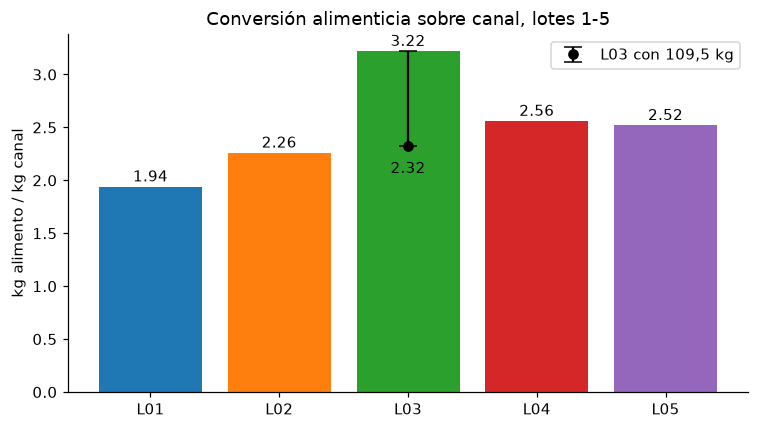

In [5]:
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(conv.index, conv.conversion, color=[COL[l] for l in conv.index])
ax.errorbar('L03', conv.conversion_alt['L03'], yerr=[[0],[conv.conversion['L03']-conv.conversion_alt['L03']]], fmt='o', color='k', capsize=6, label='L03 con 109,5 kg')
for l,v in conv.conversion.items(): ax.text(l, v+0.05, f'{v:.2f}', ha='center')
ax.text('L03', conv.conversion_alt['L03']-0.25, f"{conv.conversion_alt['L03']:.2f}", ha='center')
ax.set_ylabel('kg alimento / kg canal'); ax.set_title('Conversión alimenticia sobre canal, lotes 1-5'); ax.legend()
plt.tight_layout(); plt.savefig(G+'01_conversion_lotes.png'); plt.show()

## 2. Consumo diario y acumulado por ave vs. referencia
*La curva de referencia de la granja no trae consumo para los días 1-7, así que la fase de iniciación se compara solo en los días 8-23. El consumo real es alimento **suministrado** / aves iniciales.

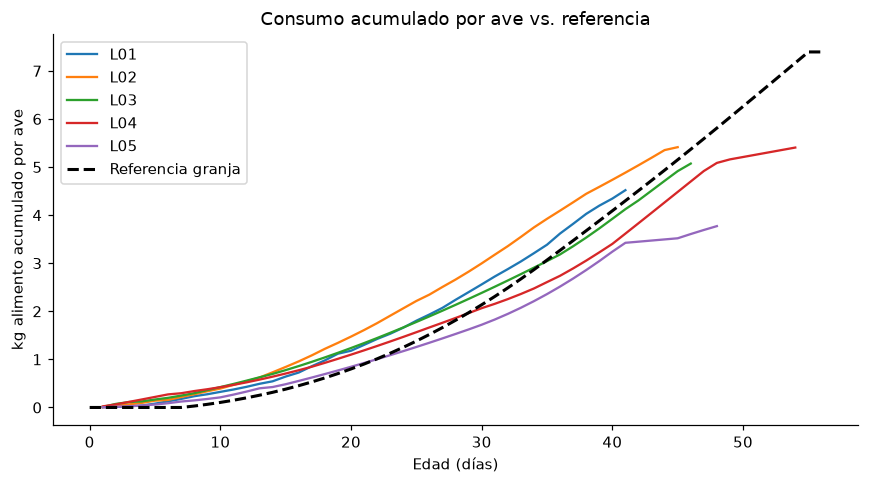

In [6]:
alim['g_ave'] = alim.apply(lambda r: r.valor/ini[r.lote], axis=1)   # sobre aves iniciales
alim = alim.sort_values(['lote','edad_dias']); alim['acum_ave'] = alim.groupby('lote').g_ave.cumsum()
fig, ax = plt.subplots(figsize=(8,4.5))
for l,g in alim.groupby('lote'): ax.plot(g.edad_dias, g.acum_ave/1000, color=COL[l], label=l)
ax.plot(ref.index, ref.acum_ref/1000, 'k--', lw=2, label='Referencia granja')
ax.set_xlabel('Edad (días)'); ax.set_ylabel('kg alimento acumulado por ave'); ax.set_title('Consumo acumulado por ave vs. referencia'); ax.legend()
plt.tight_layout(); plt.savefig(G+'02_consumo_acumulado_vs_ref.png'); plt.show()

In [7]:
# Consumo por fase (g/ave) real vs referencia (suma de la referencia en los mismos días registrados)
# La referencia de la hoja no trae consumo para los días 1-7: se comparan solo días con referencia (8+)
alim['ref_dia'] = alim.edad_dias.map(ref.consumo_ref)
fases = alim[alim.ref_dia.notna()].groupby(['lote','fase']).agg(real_g_ave=('g_ave','sum'), ref_g_ave=('ref_dia','sum'), dias=('edad_dias','count')).round(0)
fases['real_vs_ref_%'] = (100*fases.real_g_ave/fases.ref_g_ave).round(0)
fases

real_g_ave  ref_g_ave  dias  real_vs_ref_%
lote fase                                                          
L01  engorde (36+)           1134.0     1233.0     6           92.0
     iniciación (8-23)*      1355.0     1128.0    16          120.0
     levante (24-35)         1852.0     1938.0    12           96.0
L02  engorde (36+)           1490.0     2085.0    10           71.0
     iniciación (8-23)*      1691.0     1128.0    16          150.0
     levante (24-35)         2015.0     1938.0    12          104.0
L03  engorde (36+)           2028.0     2303.0    11           88.0
     iniciación (8-23)*      1306.0     1128.0    16          116.0
     levante (24-35)         1491.0     1938.0    12           77.0
L04  engorde (36+)           2798.0     4100.0    19           68.0
     iniciación (8-23)*      1076.0     1128.0    16           95.0
     levante (24-35)         1235.0     1938.0    12           64.0
L05  engorde (36+)           1414.0     2109.0    10           67.0
     iniciación (8-23)*       964.0     1128.0    16           85.0
     levante (24-35)         1271.0     1938.0    12           66.0

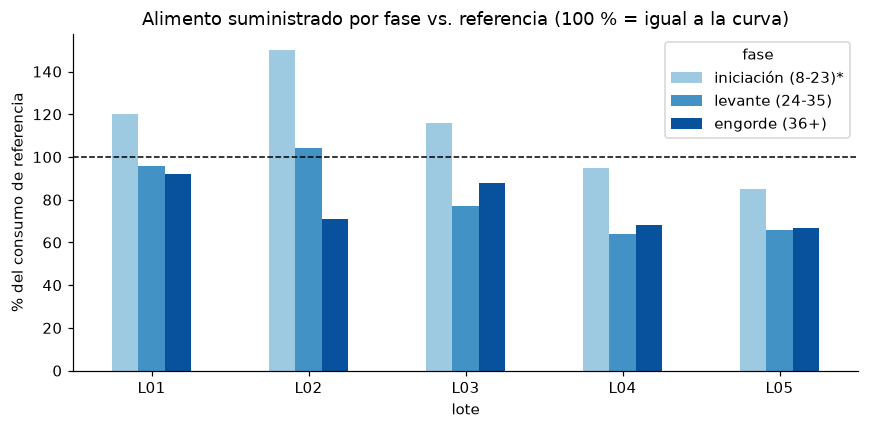

In [8]:
p = fases['real_vs_ref_%'].unstack()[['iniciación (8-23)*','levante (24-35)','engorde (36+)']]
ax = p.plot.bar(figsize=(8,4), color=['#9ecae1','#4292c6','#08519c'], rot=0)
ax.axhline(100, color='k', ls='--', lw=1); ax.set_ylabel('% del consumo de referencia')
ax.set_title('Alimento suministrado por fase vs. referencia (100 % = igual a la curva)')
plt.tight_layout(); plt.savefig(G+'03_consumo_por_fase.png'); plt.show()

## 3. Mortalidad y causas

In [9]:
mort = d[(d.variable=='mortalidad')].copy()
def causa(t):
    t = t.lower()
    for k,v in [('aplast','Aplastamiento/amontonamiento'),('estampida','Aplastamiento/amontonamiento'),('amonton','Aplastamiento/amontonamiento'),
                ('frío','Frío/lluvia'),('frio','Frío/lluvia'),('marek','Sospecha Marek/enfermedad'),('heces','Sospecha Marek/enfermedad'),('inflama','Sospecha Marek/enfermedad'),
                ('corte','Herida/sangrado'),('sangre','Herida/sangrado'),('ahog','Ahogamiento/atragantamiento'),('atragant','Ahogamiento/atragantamiento'),('desnuc','Obstrucción/cuello')]:
        if k in t: return v
    return 'Sin causa registrada'
# La causa se clasificó con esta función a partir del texto de la bitácora (texto libre no publicado)
mort['causa'] = mort.causa_mortalidad   # categoría precalculada (ver función causa) desde la bitácora
m5 = mort[mort.lote.isin(LOTES)]
print('Muertes L01-L05:', len(m5), '| mortalidad global L01-L05: %.1f %%' % (100*len(m5)/ini[LOTES].sum()))
tab = pd.crosstab(m5.causa, m5.lote, margins=True, margins_name='Total'); tab

Muertes L01-L05: 14 | mortalidad global L01-L05: 5.3 %


lote,L01,L02,L03,L04,L05,Total
causa,,,,,,
Ahogamiento/atragantamiento,0,0,1,0,0,1
Aplastamiento/amontonamiento,0,0,2,2,0,4
Frío/lluvia,0,0,0,1,0,1
Herida/sangrado,0,1,0,1,0,2
Obstrucción/cuello,0,0,1,0,0,1
Sin causa registrada,0,0,0,1,1,2
Sospecha Marek/enfermedad,1,1,0,1,0,3
Total,1,2,4,6,1,14


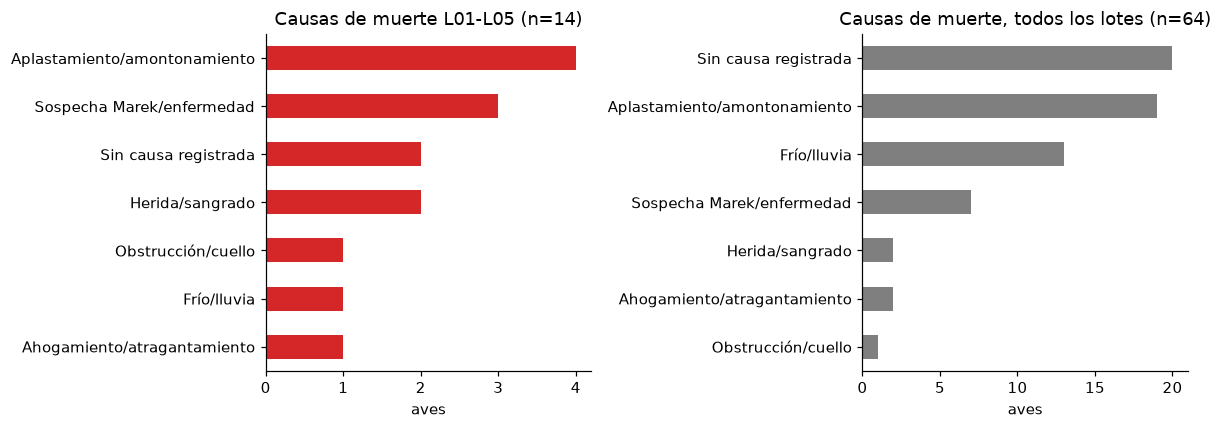

In [10]:
tot = mort.groupby('causa').size().sort_values()
fig, axs = plt.subplots(1,2, figsize=(11,4))
m5.groupby('causa').size().sort_values().plot.barh(ax=axs[0], color='#d62728'); axs[0].set_title(f'Causas de muerte L01-L05 (n={len(m5)})')
tot.plot.barh(ax=axs[1], color='#7f7f7f'); axs[1].set_title(f'Causas de muerte, todos los lotes (n={len(mort)})')
for a in axs: a.set_xlabel('aves'); a.set_ylabel('')
plt.tight_layout(); plt.savefig(G+'04_mortalidad_causas.png'); plt.show()

## 4. Agua neta vs. alimento (lotes 2-4)
Relación litros de agua consumida (suministrada − rechazada) por kg de alimento, solo en días con ambos registros. La literatura técnica suele citar ~1,6–2,0 L/kg (referencia general, no de esta granja).

In [11]:
ag = d5[d5.variable=='agua_neta_l'][['lote','edad_dias','valor']].rename(columns={'valor':'agua_l'})
ra = ag.merge(alim[['lote','edad_dias','valor']].rename(columns={'valor':'alim_g'}), on=['lote','edad_dias'])
ra = ra[ra.alim_g>0]; ra['L_por_kg'] = ra.agua_l/(ra.alim_g/1000)
razon = ra.groupby('lote').agg(dias=('edad_dias','count'), agua_total_L=('agua_l','sum'), alimento_kg=('alim_g', lambda x: x.sum()/1000))
razon['L_agua_por_kg_alimento'] = (razon.agua_total_L/razon.alimento_kg).round(2); razon.round(1)

,dias,agua_total_L,alimento_kg,L_agua_por_kg_alimento
lote,,,,
L02,42,548.5,264.2,2.1
L03,17,60.5,47.5,1.3
L04,10,35.0,25.4,1.4


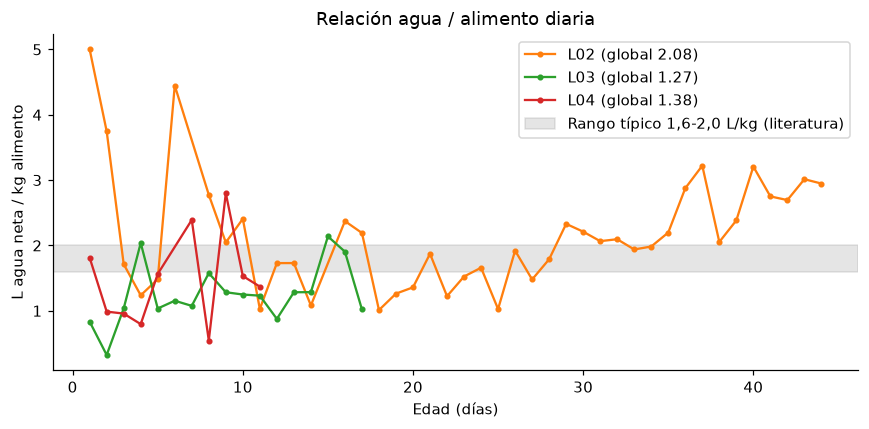

In [12]:
fig, ax = plt.subplots(figsize=(8,4))
for l,g in ra.groupby('lote'): ax.plot(g.edad_dias, g.L_por_kg, 'o-', ms=3, color=COL[l], label=f"{l} (global {razon.loc[l,'L_agua_por_kg_alimento']})")
ax.axhspan(1.6, 2.0, color='grey', alpha=.2, label='Rango típico 1,6-2,0 L/kg (literatura)')
ax.set_xlabel('Edad (días)'); ax.set_ylabel('L agua neta / kg alimento'); ax.set_title('Relación agua / alimento diaria'); ax.legend()
plt.tight_layout(); plt.savefig(G+'05_agua_vs_alimento.png'); plt.show()

## 5. Peso de lotes 3 y 4 (días 1-11) vs. referencia
Muestras de 5 aves por día (aves distintas cada día).

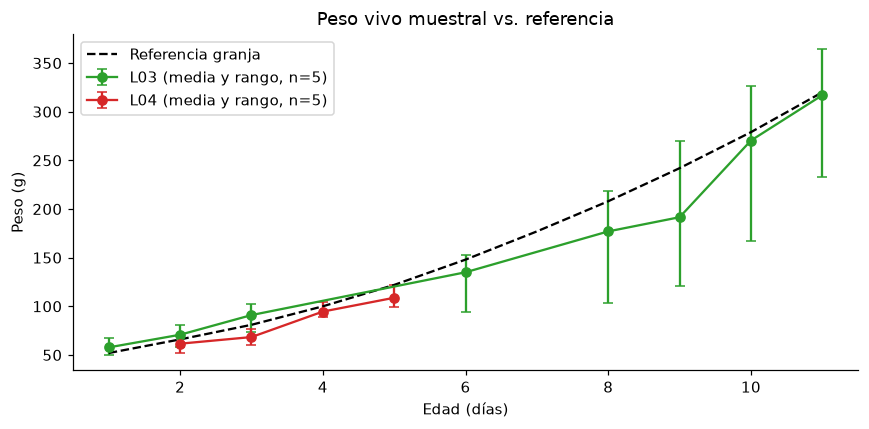

,lote,edad_dias,mean,min,max,count,ref,pct_ref
0,L03,1.0,58.0,50.0,67.0,5,52.0,111.0
1,L03,2.0,71.0,58.0,81.0,5,66.0,107.0
2,L03,3.0,91.0,74.0,102.0,5,81.0,112.0
3,L03,6.0,135.0,94.0,153.0,5,148.0,91.0
4,L03,8.0,177.0,103.0,219.0,5,208.0,85.0
5,L03,9.0,192.0,121.0,270.0,5,242.0,79.0
6,L03,10.0,270.0,167.0,326.0,5,279.0,97.0
7,L03,11.0,317.0,233.0,364.0,5,320.0,99.0
8,L04,2.0,62.0,52.0,70.0,5,66.0,93.0
9,L04,3.0,68.0,60.0,77.0,5,81.0,84.0


In [13]:
pe = d[d.variable=='peso_g'].groupby(['lote','edad_dias']).valor.agg(['mean','min','max','count']).reset_index()
pe['ref'] = pe.edad_dias.map(ref.peso_ref); pe['pct_ref'] = (100*pe['mean']/pe.ref).round(0)
fig, ax = plt.subplots(figsize=(8,4))
for l,g in pe.groupby('lote'):
    ax.errorbar(g.edad_dias, g['mean'], yerr=[g['mean']-g['min'], g['max']-g['mean']], fmt='o-', capsize=3, color=COL[l], label=f'{l} (media y rango, n=5)')
r = ref.loc[1:11]; ax.plot(r.index, r.peso_ref, 'k--', label='Referencia granja')
ax.set_xlabel('Edad (días)'); ax.set_ylabel('Peso (g)'); ax.set_title('Peso vivo muestral vs. referencia'); ax.legend()
plt.tight_layout(); plt.savefig(G+'06_peso_vs_referencia.png'); plt.show()
pe.round(0)

## 6. Ingresos y margen bruto aproximado **(estimado)**
Los registros no tienen un costo completo por lote. Supuestos tomados de anotaciones de la hoja: precio de alimento **2.425–2.758 COP/kg** (bulto de 40 kg a 97.000 COP — 194.000 por 2 bultos — y bulto de 40 kg a 110.300 COP, 24-mar-2021). No incluye mano de obra, viruta, medicamentos, energía ni transporte.

In [14]:
ing = d5[d5.variable=='ventas_cop'].groupby('lote').valor.sum().rename('ingreso_carne_cop').to_frame()
ing['ingreso_menud_cop'] = d5[d5.variable=='ventas_menudencias_cop'].groupby('lote').valor.sum()
ing = ing.fillna(0); ing['ingreso_total'] = ing.sum(axis=1)
for nom,p in [('bajo',2425),('alto',2758)]:
    ing[f'costo_alim_{nom}'] = conv.alimento_total_kg*p
ing['costo_pollitos'] = ini[LOTES]*2200
ing['margen_min (estimado)'] = ing.ingreso_total - ing.costo_alim_alto - ing.costo_pollitos
ing['margen_max (estimado)'] = ing.ingreso_total - ing.costo_alim_bajo - ing.costo_pollitos
ing['precio_prom_cop_kg'] = (ing.ingreso_carne_cop/conv.kg_vendidos).round(0)
ing.loc['Total'] = ing.sum(); ing.loc['Total','precio_prom_cop_kg'] = np.nan
ing.round(0).astype('Int64', errors='ignore')

,ingreso_carne_cop,ingreso_menud_cop,ingreso_total,costo_alim_bajo,costo_alim_alto,costo_pollitos,margen_min (estimado),margen_max (estimado),precio_prom_cop_kg
lote,,,,,,,,,
L01,838308,0,838308,547953,623198,110000,105110,180355,7184
L02,974000,0,974000,669518,761456,112200,100344,192282,7984
L03,630800,0,630800,615028,699484,110000,-178684,-94228,7999
L04,1114220,0,1114220,799595,909395,134200,70625,180425,8641
L05,707300,35000,742300,466449,530501,112200,99599,163651,9253
Total,4264628,35000,4299628,3098544,3524034,578600,196994,622484,<NA>


## 7. Calidad de datos (hallazgo, no solo limitación)

In [15]:
# 7.1 Balance de aves por lote: lo que entra debe ser igual a lo que sale
bal = res[~res.lote.str.contains('\\+')].set_index('lote')[['aves_iniciales','muertes_tabla_original','desaparecidas','vendidas','sin_explicar']]
bal.columns = ['iniciales','muertes','desaparecidas','vendidas','sin_explicar']
bal['nota'] = np.where(bal.vendidas==0, 'ventas registradas en grupo combinado', np.where(bal.sin_explicar>0,'faltan aves', np.where(bal.sin_explicar<0,'se vendieron más de las que había','cuadra')))
print('Lotes que cuadran:', (bal.sin_explicar==0).sum(), 'de', len(bal)); bal

Lotes que cuadran: 3 de 17


,iniciales,muertes,desaparecidas,vendidas,sin_explicar,nota
lote,,,,,,
L01,50.0,1.0,0.0,48.0,1.0,faltan aves
L02,51.0,2.0,0.0,49.0,0.0,cuadra
L03,50.0,4.0,0.0,36.0,10.0,faltan aves
L04,61.0,6.0,0.0,63.0,-8.0,se vendieron más de las que había
L05,51.0,1.0,7.0,40.0,3.0,faltan aves
L06,50.0,0.0,2.0,49.0,-1.0,se vendieron más de las que había
L07,40.0,4.0,1.0,42.0,-7.0,se vendieron más de las que había
L08,50.0,4.0,0.0,27.0,19.0,faltan aves
L09,50.0,1.0,0.0,49.0,0.0,cuadra


In [16]:
# 7.2 % de completitud por variable y lote (días con dato / días del ciclo según alimento)
ciclo = alim.groupby('lote').edad_dias.max()
vars_ = ['alimento_g','agua_l','agua_rechazo_l','agua_ml_ave','peso_g']
comp = pd.DataFrame(index=LOTES, columns=vars_, dtype=float)
for l in LOTES:
    for v in vars_:
        x = d5[(d5.lote==l)&(d5.variable==v)&d5.valor.notna()]
        comp.loc[l,v] = 100*x.edad_dias.nunique()/ciclo[l]
comp['ventas_con_kg_%'] = [100*(1-((d5.lote==l)&(d5.variable=='ventas_unidades')&d5.flag.str.contains('sin_peso')).sum()/max(1,((d5.lote==l)&(d5.variable=='ventas_unidades')).sum())) for l in LOTES]
comp = comp.round(0); comp

,alimento_g,agua_l,agua_rechazo_l,agua_ml_ave,peso_g,ventas_con_kg_%
L01,100.0,0.0,0.0,0.0,0.0,100.0
L02,100.0,93.0,93.0,87.0,0.0,100.0
L03,100.0,39.0,37.0,9.0,17.0,100.0
L04,100.0,22.0,19.0,0.0,7.0,83.0
L05,94.0,0.0,0.0,0.0,0.0,89.0


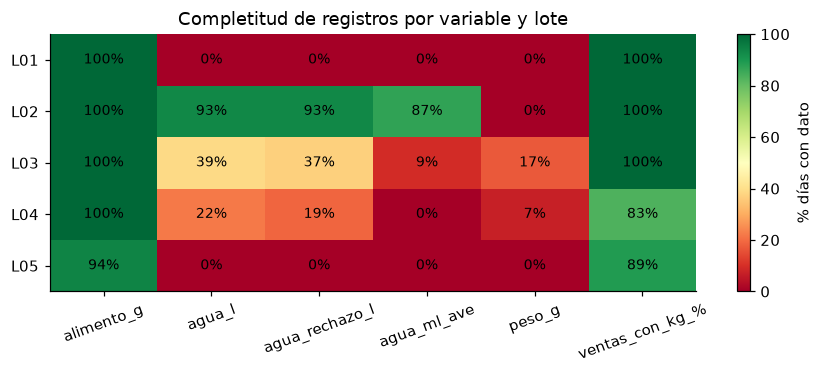

In [17]:
fig, ax = plt.subplots(figsize=(8,3.5))
im = ax.imshow(comp.values.astype(float), cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(comp.shape[1]), comp.columns, rotation=20); ax.set_yticks(range(len(LOTES)), LOTES)
for i in range(comp.shape[0]):
    for j in range(comp.shape[1]): ax.text(j,i,f'{comp.iloc[i,j]:.0f}%',ha='center',va='center',fontsize=9)
plt.colorbar(im, label='% días con dato'); ax.set_title('Completitud de registros por variable y lote')
plt.tight_layout(); plt.savefig(G+'07_completitud_datos.png'); plt.show()

In [18]:
# 7.3 Ventas sin kg y mortalidad sin fecha (todos los lotes)
vu = d[d.variable=='ventas_unidades']; sk = vu[vu.flag.str.contains('sin_peso')]
print(f'Ventas sin kg: {len(sk)} de {len(vu)} registros ({100*len(sk)/len(vu):.0f} %), {sk.valor.sum():.0f} aves de {vu.valor.sum():.0f} vendidas')
print(sk.groupby('lote').valor.agg(['count','sum']).rename(columns={'count':'registros','sum':'aves'}).T)
sf = mort[mort.fecha.isna()]
print(f'\nMortalidad sin fecha: {len(sf)} de {len(mort)} eventos ({100*len(sf)/len(mort):.0f} %), lotes {sorted(sf.lote.unique())}')
print('Mortalidad sin causa registrada:', (mort.causa=='Sin causa registrada').sum())

Ventas sin kg: 30 de 89 registros (34 %), 189 aves de 776 vendidas
lote       L04  L05   L06  L08  L10  L12+L13  L14+L15   L16
registros  1.0  1.0   3.0  1.0  3.0      7.0      9.0   5.0
aves       4.0  1.0  19.0  7.0  6.0     55.0     72.0  25.0

Mortalidad sin fecha: 16 de 64 eventos (25 %), lotes ['L13', 'L14', 'L15']
Mortalidad sin causa registrada: 20


### Recomendación: formato mínimo diario para una granja pequeña
Una sola fila por lote y día (hoja o formulario en el celular):

| fecha | lote | aves_vivas_inicio | alimento_servido_kg | alimento_sobrante_kg | agua_servida_L | agua_sobrante_L | muertes | causa_muerte | aves_vendidas | kg_vendidos | valor_COP | temp_min/max | observación |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|

Reglas: (1) fecha siempre en formato fecha, nunca texto; (2) **cada venta con kg y unidades**; (3) una fila por muerte con causa de una lista corta; (4) pesar 10 aves fijas cada 7 días; (5) cierre de lote: iniciales = muertes + desaparecidas + vendidas; (6) registrar compras (bultos, pollitos) con precio para poder sacar margen; (7) un lote por venta (no combinar lotes).